# PN Detection Residual U-Net — v4.0 architecture ablation

This notebook is a controlled architecture experiment based on the v3.0 training workflow.
It uses the v6.0 synthetic dataset and keeps the loss, optimizer, normalization, data split
logic, `val_loss` checkpointing, detection metrics, and threshold-selection workflow unchanged.

**Only the network blocks are changed:** each plain two-convolution U-Net block is replaced by
a residual block with an identity shortcut when channel dimensions match and a 1×1 projection
shortcut when they do not. The encoder/decoder depth and feature widths remain
`32 → 64 → 128 → 256`.


In [24]:
import os
SEED=42
os.environ["PYTHONHASHSEED"]=str(SEED)
os.environ["TF_DETERMINISTIC_OPS"]="1"

from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import maximum_filter

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:",tf.__version__)

TensorFlow version: 2.21.0


In [25]:
DATA_PATH=Path("all_PN_10000_grouped_norm_v6.2_diffuse_HII.npz")
MODEL_PATH=Path("best_PN_ResUNet_focal_all_grouped_v4.3.keras")
NORM_PATH=Path("PN_ResUNet_normalization_v4.3.npz")
SPLIT_PATH=Path("PN_ResUNet_split_manifest_v4.3.npz")
CONFIG_PATH=Path("PN_ResUNet_training_config_v4.3.json")

FLUX_SCALE=1e18
ASINH_PERCENTILE=90.0
BATCH_SIZE=32
LEARNING_RATE=3e-4
WEIGHT_DECAY=1e-5
CLIPNORM=1.0
MAX_EPOCHS=100

PEAK_THRESHOLD=0.30
MIN_DISTANCE=3
MATCH_TOLERANCE=1.0

COMPACT_NEGATIVE_TYPES=["compact_nonpn","compact_non-pn","nonpn_compact","hard_negative"]
BACKGROUND_TYPES=["background","empty","blank"]


## Load dataset

In [26]:
data=np.load(DATA_PATH,allow_pickle=True)
X=data["X"].astype(np.float32)
Y=data["Y"].astype(np.float32)
line_names=data["line_names"]
saved_channel_means=data["channel_means"].astype(np.float32)
saved_channel_stds=data["channel_stds"].astype(np.float32)
metadata=json.loads(data["metadata_json"].item())

group_key=next((k for k in ("group_ids","parent_ids","split_group_ids") if k in data.files),None)
type_key=next((k for k in ("sample_types","sample_type","source_types") if k in data.files),None)

if group_key is None:
    raise KeyError("Dataset is missing leakage-safe group IDs.")
if type_key is None:
    raise KeyError("Dataset is missing sample_types.")

group_ids=np.asarray(data[group_key]).astype(str)
sample_types=np.char.lower(np.asarray(data[type_key]).astype(str))

if len(group_ids)!=len(X) or len(sample_types)!=len(X):
    raise ValueError("group_ids and sample_types must have length N.")

print("Original X shape:",X.shape)
print("Original Y shape:",Y.shape)
print("Lines:",line_names)
print("Unique groups:",len(np.unique(group_ids)))
print("Sample types:")
for name,count in zip(*np.unique(sample_types,return_counts=True)):
    print(f"  {name}: {count}")

Original X shape: (10000, 4, 64, 64)
Original Y shape: (10000, 1, 64, 64)
Lines: ['Hbeta' 'OIII5007' 'Halpha' 'NII6584']
Unique groups: 139
Sample types:
  background: 197
  compact_nonpn: 4637
  diffuse_nonpn: 96
  pn: 5070


In [27]:
X=np.transpose(X,(0,2,3,1))
Y=np.transpose(Y,(0,2,3,1))

assert X.ndim==4 and X.shape[-1]==4
assert Y.ndim==4 and Y.shape[-1]==1
assert X.shape[1:3]==(64,64)
assert Y.shape[1:3]==(64,64)

print("Transposed X shape:",X.shape)
print("Transposed Y shape:",Y.shape)

Transposed X shape: (10000, 64, 64, 4)
Transposed Y shape: (10000, 64, 64, 1)


## Recover unstandardized inputs if needed

In [28]:
current_means=X.mean(axis=(0,1,2),dtype=np.float64)
current_stds=X.std(axis=(0,1,2),dtype=np.float64)
already_standardized=np.all(np.abs(current_means)<0.1) and np.all(np.abs(current_stds-1.0)<0.1)

print("Current means:",current_means)
print("Current stds:",current_stds)
print("Looks already standardized:",already_standardized)

if already_standardized:
    X=(X*saved_channel_stds[None,None,None,:]+saved_channel_means[None,None,None,:]).astype(np.float32)
    print("Recovered approximately raw inputs using saved dataset statistics.")
else:
    X=X.astype(np.float32,copy=True)
    print("Inputs already appear unstandardized.")

if not np.all(np.isfinite(X)):
    raise ValueError("X contains NaN or Inf values.")
if not np.all(np.isfinite(Y)):
    raise ValueError("Y contains NaN or Inf values.")

Current means: [ 3.26943484e-11 -8.36500274e-11  4.91441304e-12 -7.08125622e-11]
Current stds: [1.00000002 1.00000001 0.99999999 1.        ]
Looks already standardized: True
Recovered approximately raw inputs using saved dataset statistics.


## Inspect one sample

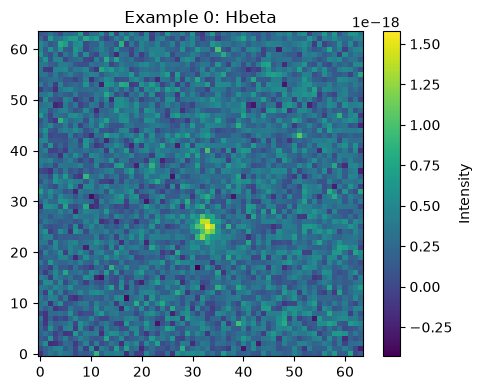

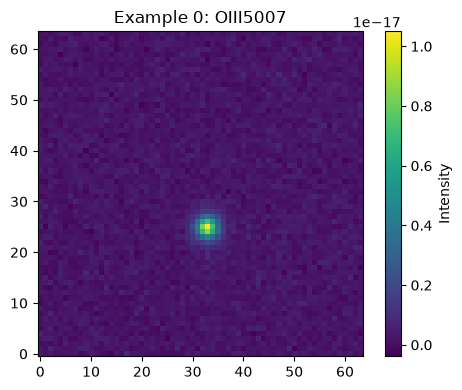

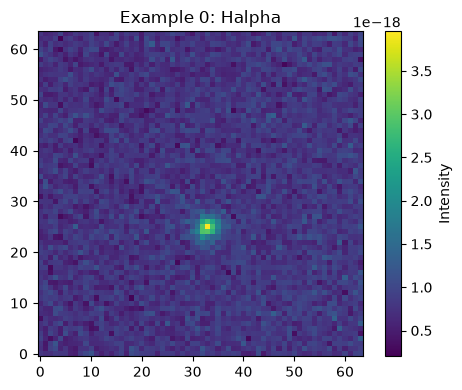

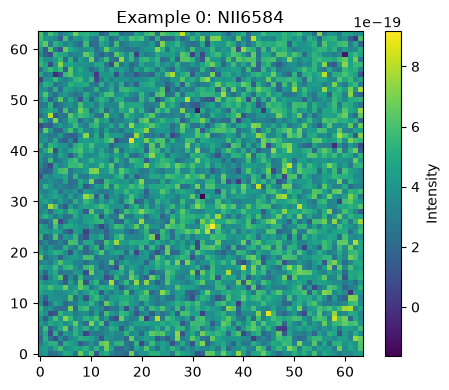

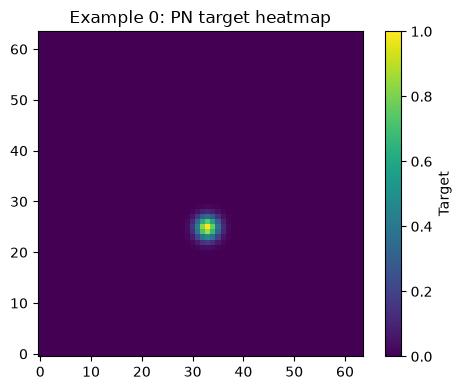

In [29]:
i=0
for c,name in enumerate(line_names):
    plt.figure(figsize=(5,4))
    plt.imshow(X[i,:,:,c],origin="lower")
    plt.colorbar(label="Intensity")
    plt.title(f"Example {i}: {name}")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(5,4))
plt.imshow(Y[i,:,:,0],origin="lower")
plt.colorbar(label="Target")
plt.title(f"Example {i}: PN target heatmap")
plt.tight_layout()
plt.show()

## Leakage-safe train / validation / test split

In [30]:
has_pn=np.any(Y>=0.999,axis=(1,2,3)).astype(np.int32)

def best_group_holdout(indices,groups,labels,holdout_fraction,seed,n_trials=200):
    indices=np.asarray(indices)
    groups=np.asarray(groups)
    labels=np.asarray(labels)
    if len(np.unique(groups[indices]))<2:
        raise ValueError("Not enough independent groups for leakage-safe splitting.")
    overall_pos=labels[indices].mean()
    target_n=holdout_fraction*len(indices)
    best=None
    for t in range(n_trials):
        splitter=GroupShuffleSplit(n_splits=1,test_size=holdout_fraction,random_state=seed+t)
        keep_local,hold_local=next(splitter.split(np.zeros(len(indices)),labels[indices],groups=groups[indices]))
        keep_idx=indices[keep_local]
        hold_idx=indices[hold_local]
        hold_error=abs(len(hold_idx)-target_n)/max(len(indices),1)
        balance_error=abs(labels[keep_idx].mean()-overall_pos)+abs(labels[hold_idx].mean()-overall_pos)
        score=hold_error+balance_error
        if best is None or score<best[0]:
            best=(score,keep_idx,hold_idx)
    return best[1],best[2]

all_idx=np.arange(len(X))
train_idx,temp_idx=best_group_holdout(all_idx,group_ids,has_pn,0.20,SEED)
val_idx,test_idx=best_group_holdout(temp_idx,group_ids,has_pn,0.50,SEED+1000)

train_groups=set(group_ids[train_idx])
val_groups=set(group_ids[val_idx])
test_groups=set(group_ids[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

types_train=sample_types[train_idx]
types_val=sample_types[val_idx]
types_test=sample_types[test_idx]

def split_report(name,idx,types):
    compact=np.isin(types,COMPACT_NEGATIVE_TYPES)
    background=np.isin(types,BACKGROUND_TYPES)
    print(f"{name:5s}: N={len(idx):5d} | groups={len(np.unique(group_ids[idx])):4d} | PN-containing={has_pn[idx].mean():.3f} | compact non-PN={compact.sum():4d} | background={background.sum():4d}")

print("Leakage-safe split:")
split_report("Train",train_idx,types_train)
split_report("Val",val_idx,types_val)
split_report("Test",test_idx,types_test)

negative_train=~has_pn[train_idx].astype(bool)
compact_negative_train=negative_train&np.isin(types_train,COMPACT_NEGATIVE_TYPES)

if negative_train.sum()==0:
    raise ValueError("Training set contains no negative samples.")

compact_fraction=compact_negative_train.sum()/negative_train.sum()
print(f"Fraction of training negatives that are compact non-PNe: {compact_fraction:.3f}")

if compact_fraction<0.5:
    print("WARNING: realistic compact non-PNe do not dominate the negative training set.")

Leakage-safe split:
Train: N= 7993 | groups= 111 | PN-containing=0.507 | compact non-PN=3716 | background= 156
Val  : N= 1002 | groups=  14 | PN-containing=0.508 | compact non-PN= 461 | background=  18
Test : N= 1005 | groups=  14 | PN-containing=0.506 | compact non-PN= 460 | background=  23
Fraction of training negatives that are compact non-PNe: 0.943


## Robust asinh preprocessing + train-only standardization

In [31]:
def calculate_asinh_scale(x,indices,percentile):
    scales=np.zeros(x.shape[-1],dtype=np.float64)
    for c in range(x.shape[-1]):
        values=x[indices,:,:,c].astype(np.float32)*np.float32(FLUX_SCALE)
        values=np.abs(values[np.isfinite(values)])
        scales[c]=np.percentile(values,percentile)
        if not np.isfinite(scales[c]) or scales[c]<=0:
            raise ValueError(f"Invalid asinh scale for channel {c}: {scales[c]}")
    return scales

asinh_scale=calculate_asinh_scale(X,train_idx,ASINH_PERCENTILE)
asinh_scale32=asinh_scale.astype(np.float32)

def asinh_transform(x):
    x_scaled=x.astype(np.float32)*np.float32(FLUX_SCALE)
    return np.arcsinh(x_scaled/asinh_scale32[None,None,None,:]).astype(np.float32)

X_train_transformed=asinh_transform(X[train_idx])
channel_means=np.mean(X_train_transformed,axis=(0,1,2),dtype=np.float64)
channel_stds=np.std(X_train_transformed,axis=(0,1,2),dtype=np.float64)

if np.any(~np.isfinite(channel_means)):
    raise ValueError(f"Invalid channel means: {channel_means}")
if np.any(~np.isfinite(channel_stds)) or np.any(channel_stds<=0):
    raise ValueError(f"Invalid channel standard deviations: {channel_stds}")

mean32=channel_means.astype(np.float32)
std32=channel_stds.astype(np.float32)

X_train=((X_train_transformed-mean32[None,None,None,:])/std32[None,None,None,:]).astype(np.float32)
del X_train_transformed

def normalize_indices(indices):
    transformed=asinh_transform(X[indices])
    return ((transformed-mean32[None,None,None,:])/std32[None,None,None,:]).astype(np.float32)

X_val=normalize_indices(val_idx)
X_test=normalize_indices(test_idx)
Y_train=Y[train_idx].astype(np.float32)
Y_val=Y[val_idx].astype(np.float32)
Y_test=Y[test_idx].astype(np.float32)

print("FLUX_SCALE:",FLUX_SCALE)
print("ASINH_PERCENTILE:",ASINH_PERCENTILE)
print("ASINH scales:",asinh_scale)
print("Train-only transformed means:",channel_means)
print("Train-only transformed stds:",channel_stds)
print("Normalized train means:",X_train.mean(axis=(0,1,2),dtype=np.float64))
print("Normalized train stds:",X_train.std(axis=(0,1,2),dtype=np.float64))

FLUX_SCALE: 1e+18
ASINH_PERCENTILE: 90.0
ASINH scales: [ 3.8339839   2.39888287 16.48641014  7.38966751]
Train-only transformed means: [0.50547658 0.46667172 0.48084732 0.45404726]
Train-only transformed stds: [0.83922711 0.61886435 0.85327488 0.75691231]
Normalized train means: [-1.80276558e-08  2.01858498e-08 -1.21134769e-08  5.47652183e-09]
Normalized train stds: [0.99999998 0.99999998 0.99999999 1.00000003]


In [32]:
np.savez(
    SPLIT_PATH,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    train_groups=np.asarray(sorted(train_groups)),
    val_groups=np.asarray(sorted(val_groups)),
    test_groups=np.asarray(sorted(test_groups))
)
print("Saved split manifest:",SPLIT_PATH)

Saved split manifest: PN_ResUNet_split_manifest_v4.3.npz


## Deterministic augmentation and tf.data pipelines

In [33]:
def augment(index,x,y):
    index=tf.cast(index,tf.int32)
    seed=tf.stack([tf.cast(SEED,tf.int32),index])
    seeds=tf.random.experimental.stateless_split(seed,3)

    k=tf.random.stateless_uniform([],seed=seeds[0],minval=0,maxval=4,dtype=tf.int32)
    x=tf.image.rot90(x,k)
    y=tf.image.rot90(y,k)

    do_lr=tf.random.stateless_uniform([],seed=seeds[1])>0.5
    x=tf.cond(do_lr,lambda:tf.image.flip_left_right(x),lambda:x)
    y=tf.cond(do_lr,lambda:tf.image.flip_left_right(y),lambda:y)

    do_ud=tf.random.stateless_uniform([],seed=seeds[2])>0.5
    x=tf.cond(do_ud,lambda:tf.image.flip_up_down(x),lambda:x)
    y=tf.cond(do_ud,lambda:tf.image.flip_up_down(y),lambda:y)
    return x,y

options=tf.data.Options()
options.experimental_deterministic=True

train_ds=(
    tf.data.Dataset.from_tensor_slices((X_train,Y_train))
    .shuffle(len(X_train),seed=SEED,reshuffle_each_iteration=True)
    .enumerate()
    .map(lambda idx,data:augment(idx,data[0],data[1]),num_parallel_calls=tf.data.AUTOTUNE,deterministic=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(options)
)

val_ds=(
    tf.data.Dataset.from_tensor_slices((X_val,Y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(options)
)

test_ds=(
    tf.data.Dataset.from_tensor_slices((X_test,Y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(options)
)

## U-Net model

In [34]:
def residual_block(x, filters, name=None):
    """Two 3x3 convolutions with a residual shortcut.

    The shortcut is identity when x already has `filters` channels; otherwise a
    1x1 projection + BatchNorm is used so the tensors can be added.
    """
    shortcut = x

    y = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal",
        name=None if name is None else f"{name}_conv1",
    )(x)
    y = layers.BatchNormalization(
        name=None if name is None else f"{name}_bn1"
    )(y)
    y = layers.ReLU(
        name=None if name is None else f"{name}_relu1"
    )(y)

    y = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal",
        name=None if name is None else f"{name}_conv2",
    )(y)
    y = layers.BatchNormalization(
        name=None if name is None else f"{name}_bn2"
    )(y)

    if x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1, padding="same", use_bias=False,
            kernel_initializer="he_normal",
            name=None if name is None else f"{name}_proj",
        )(shortcut)
        shortcut = layers.BatchNormalization(
            name=None if name is None else f"{name}_proj_bn"
        )(shortcut)

    y = layers.Add(
        name=None if name is None else f"{name}_add"
    )([y, shortcut])
    y = layers.ReLU(
        name=None if name is None else f"{name}_out"
    )(y)
    return y


def build_unet(input_shape=(64, 64, 4)):
    inputs = keras.Input(shape=input_shape)

    c1 = residual_block(inputs, 32, name="enc1")
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = residual_block(p1, 64, name="enc2")
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = residual_block(p2, 128, name="enc3")
    p3 = layers.MaxPooling2D((2, 2))(c3)

    b = residual_block(p3, 256, name="bottleneck")
    b = layers.Dropout(0.20)(b)

    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(b)
    u3 = layers.Concatenate()([u3, c3])
    c4 = residual_block(u3, 128, name="dec3")

    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = residual_block(u2, 64, name="dec2")

    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = residual_block(u1, 32, name="dec1")

    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="pn_heatmap")(c6)
    return keras.Model(inputs, outputs, name="PN_ResUNet")


## Focal loss

In [35]:
@tf.keras.utils.register_keras_serializable()
def center_focal_loss(y_true,y_pred):
    eps=1e-6
    y_pred=tf.clip_by_value(y_pred,eps,1.0-eps)
    positive=tf.cast(y_true>=0.999,tf.float32)
    negative=tf.cast(y_true<0.999,tf.float32)
    negative_weights=tf.pow(1.0-y_true,4.0)
    positive_loss=-tf.math.log(y_pred)*tf.pow(1.0-y_pred,2.0)*positive
    negative_loss=-tf.math.log(1.0-y_pred)*tf.pow(y_pred,2.0)*negative_weights*negative
    num_positive=tf.reduce_sum(positive)
    total_loss=tf.reduce_sum(positive_loss)+tf.reduce_sum(negative_loss)
    return total_loss/tf.maximum(num_positive,1.0)

## Source-level detection metrics

In [36]:
def find_pn_centers(heatmap,threshold=0.30,min_distance=3):
    size=2*min_distance+1
    local_max=heatmap==maximum_filter(heatmap,size=size,mode="constant")
    detected=local_max&(heatmap>=threshold)
    y,x=np.where(detected)
    scores=heatmap[y,x]
    order=np.argsort(scores)[::-1]
    return np.column_stack([x[order],y[order],scores[order]])

def find_true_centers(target,threshold=0.999,min_distance=1):
    size=2*min_distance+1
    local_max=target==maximum_filter(target,size=size,mode="constant")
    detected=local_max&(target>=threshold)
    y,x=np.where(detected)
    return np.column_stack([x,y]).astype(np.float32)

def match_detections(predicted,true_centers,tolerance=1.0):
    if len(predicted)==0:
        return 0,0,len(true_centers),[]
    if len(true_centers)==0:
        return 0,len(predicted),0,[]
    pred_xy=np.asarray(predicted[:,:2],dtype=np.float32)
    true_xy=np.asarray(true_centers,dtype=np.float32)
    used_true=set()
    tp=0
    localization_errors=[]
    for px,py in pred_xy:
        distances=np.sqrt((true_xy[:,0]-px)**2+(true_xy[:,1]-py)**2)
        for j in np.argsort(distances):
            if distances[j]>tolerance:
                break
            if j not in used_true:
                used_true.add(j)
                tp+=1
                localization_errors.append(float(distances[j]))
                break
    fp=len(pred_xy)-tp
    fn=len(true_xy)-tp
    return tp,fp,fn,localization_errors

def evaluate_detector(model,X_eval,Y_eval,threshold=0.30,min_distance=3,match_tolerance=1.0,verbose=0):
    predictions=model.predict(X_eval,batch_size=BATCH_SIZE,verbose=verbose)
    total_tp=total_fp=total_fn=0
    total_tn=total_negative_images=total_negative_images_with_fp=0
    all_errors=[]
    for pred_map,true_map in zip(predictions,Y_eval):
        pred_centers=find_pn_centers(pred_map[:,:,0],threshold,min_distance)
        true_centers=find_true_centers(true_map[:,:,0])
        if len(true_centers)==0:
            total_negative_images+=1
            if len(pred_centers)==0:
                total_tn+=1
            else:
                total_negative_images_with_fp+=1
        tp,fp,fn,errors=match_detections(pred_centers,true_centers,match_tolerance)
        total_tp+=tp
        total_fp+=fp
        total_fn+=fn
        all_errors.extend(errors)
    precision=total_tp/(total_tp+total_fp) if total_tp+total_fp else 0.0
    recall=total_tp/(total_tp+total_fn) if total_tp+total_fn else 0.0
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    specificity=total_tn/total_negative_images if total_negative_images else np.nan
    fp_image_rate=total_negative_images_with_fp/total_negative_images if total_negative_images else np.nan
    errors=np.asarray(all_errors,dtype=np.float32)
    return {
        "TP":total_tp,
        "FP":total_fp,
        "FN":total_fn,
        "TN":total_tn,
        "negative_images":total_negative_images,
        "negative_images_with_FP":total_negative_images_with_fp,
        "specificity":specificity,
        "false_positive_image_rate":fp_image_rate,
        "precision":precision,
        "recall":recall,
        "f1":f1,
        "mean_localization_error":float(np.mean(errors)) if len(errors) else np.nan,
        "median_localization_error":float(np.median(errors)) if len(errors) else np.nan,
        "rmse_localization_error":float(np.sqrt(np.mean(errors**2))) if len(errors) else np.nan,
        "std_localization_error":float(np.std(errors)) if len(errors) else np.nan,
        "localization_errors":errors
    }

def negative_subset_fp_rate(model,X_subset,Y_subset,type_subset,threshold):
    pred_all=model.predict(X_subset,batch_size=BATCH_SIZE,verbose=0)
    rows=[]
    for target_type,aliases in {"compact_nonpn":COMPACT_NEGATIVE_TYPES,"background":BACKGROUND_TYPES}.items():
        mask=np.isin(type_subset,aliases)
        mask&=~np.any(Y_subset>=0.999,axis=(1,2,3))
        n=int(mask.sum())
        if n==0:
            rows.append((target_type,0,np.nan))
            continue
        with_fp=0
        for pred_map in pred_all[mask]:
            detections=find_pn_centers(pred_map[:,:,0],threshold,MIN_DISTANCE)
            with_fp+=int(len(detections)>0)
        rows.append((target_type,n,with_fp/n))
    print("negative_type     N     image_FP_rate")
    for name,n,rate in rows:
        print(f"{name:15s} {n:5d}   {rate:.3f}" if np.isfinite(rate) else f"{name:15s} {n:5d}   nan")

## Build and compile

In [37]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model=build_unet()

optimizer=keras.optimizers.AdamW(
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    clipnorm=CLIPNORM
)

model.compile(optimizer=optimizer,loss=center_focal_loss)
model.summary()

with open("model_summary_resunet_v4.0.txt","w") as f:
    model.summary(print_fn=lambda line:f.write(line+"\n"))

Model: "PN_ResUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 4) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, 64, 64,    │      1,152 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_bn1            │ (None, 64, 64,    │        128 │ enc1_conv1[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_relu1 (ReLU)   │ (None, 64, 64,    │          0 │ enc1_bn1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, 64, 64,    │      9,216 │ enc1_relu1[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_proj (Conv2D)  │ (None, 64, 64,    │        128 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_bn2            │ (None, 64, 64,    │        128 │ enc1_conv2[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_proj_bn        │ (None, 64, 64,    │        128 │ enc1_proj[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_add (Add)      │ (None, 64, 64,    │          0 │ enc1_bn2[0][0],   │
│                     │ 32)               │            │ enc1_proj_bn[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_out (ReLU)     │ (None, 64, 64,    │          0 │ enc1_add[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ enc1_out[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, 32, 32,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_bn1            │ (None, 32, 32,    │        256 │ enc2_conv1[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_relu1 (ReLU)   │ (None, 32, 32,    │          0 │ enc2_bn1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv2D) │ (None, 32, 32,    │     36,864 │ enc2_relu1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_proj (Conv2D)  │ (None, 32, 32,    │      2,048 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_bn2            │ (None, 32, 32,    │        256 │ enc2_conv2[0][0]

 Total params: 2,019,073 (7.70 MB)

 Trainable params: 2,014,849 (7.69 MB)

 Non-trainable params: 4,224 (16.50 KB)

## Callbacks

In [38]:
class DetectionMetricsLogger(keras.callbacks.Callback):
    def __init__(self,X_val,Y_val,threshold,min_distance,match_tolerance):
        super().__init__()
        self.X_val=X_val
        self.Y_val=Y_val
        self.threshold=threshold
        self.min_distance=min_distance
        self.match_tolerance=match_tolerance
        self.precision=[]
        self.recall=[]
        self.f1=[]

    def on_epoch_end(self,epoch,logs=None):
        m=evaluate_detector(
            self.model,self.X_val,self.Y_val,
            threshold=self.threshold,
            min_distance=self.min_distance,
            match_tolerance=self.match_tolerance,
            verbose=0
        )
        self.precision.append(m["precision"])
        self.recall.append(m["recall"])
        self.f1.append(m["f1"])
        if logs is not None:
            logs["val_source_precision"]=m["precision"]
            logs["val_source_recall"]=m["recall"]
            logs["val_source_f1"]=m["f1"]
        print(f" - val_source_precision: {m['precision']:.4f} - val_source_recall: {m['recall']:.4f} - val_source_f1: {m['f1']:.4f}")

class LearningRateLogger(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.values=[]

    def on_epoch_end(self,epoch,logs=None):
        lr=float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        self.values.append(lr)
        if logs is not None:
            logs["learning_rate_logged"]=lr

detection_logger=DetectionMetricsLogger(
    X_val,Y_val,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE
)

lr_logger=LearningRateLogger()

callbacks=[
    keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    detection_logger,
    lr_logger
]

## Train

In [39]:
history=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks
)

Epoch 1/100


/home/gsafari/miniconda3/envs/tensorflow-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1789907604.640188 3859705 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/PN_ResUNet_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 52.3805
Epoch 1: val_loss improved from None to 0.75796, saving model to best_PN_ResUNet_focal_all_grouped_v4.3.keras

Epoch 1: finished saving model to best_PN_ResUNet_focal_all_grouped_v4.3.keras


E0000 00:00:1789907615.033416 3859705 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.6312 - val_source_recall: 0.7953 - val_source_f1: 0.7038
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - loss: 52.2204 - val_loss: 0.7580 - learning_rate: 3.0000e-04 - val_source_precision: 0.6312 - val_source_recall: 0.7953 - val_source_f1: 0.7038 - learning_rate_logged: 3.0000e-04
Epoch 2/100
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.5401
Epoch 2: val_loss improved from 0.75796 to 0.51673, saving model to best_PN_ResUNet_focal_all_grouped_v4.3.keras

Epoch 2: finished saving model to best_PN_ResUNet_focal_all_grouped_v4.3.keras


...

 - val_source_precision: 0.8338 - val_source_recall: 0.9346 - val_source_f1: 0.8813
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - loss: 0.1220 - val_loss: 0.2458 - learning_rate: 7.5000e-05 - val_source_precision: 0.8338 - val_source_recall: 0.9346 - val_source_f1: 0.8813 - learning_rate_logged: 3.7500e-05
Epoch 40/100
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.1155
Epoch 40: val_loss did not improve from 0.23542


E0000 00:00:1789907975.823660 3859705 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.8328 - val_source_recall: 0.9362 - val_source_f1: 0.8815
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - loss: 0.1157 - val_loss: 0.2487 - learning_rate: 3.7500e-05 - val_source_precision: 0.8328 - val_source_recall: 0.9362 - val_source_f1: 0.8815 - learning_rate_logged: 3.7500e-05
Epoch 41/100
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.1203
Epoch 41: val_loss did not improve from 0.23542


E0000 00:00:1789907985.070563 3859705 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.8338 - val_source_recall: 0.9346 - val_source_f1: 0.8813
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - loss: 0.1202 - val_loss: 0.2504 - learning_rate: 3.7500e-05 - val_source_precision: 0.8338 - val_source_recall: 0.9346 - val_source_f1: 0.8813 - learning_rate_logged: 3.7500e-05
Epoch 41: early stopping
Restoring model weights from the end of the best epoch: 29.


## Training curves

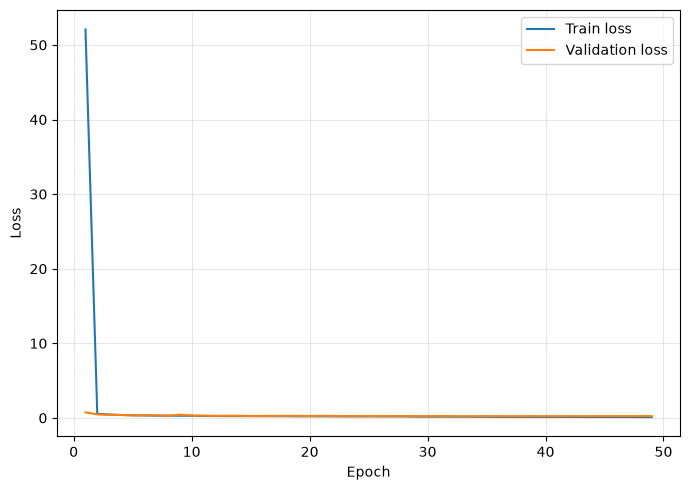

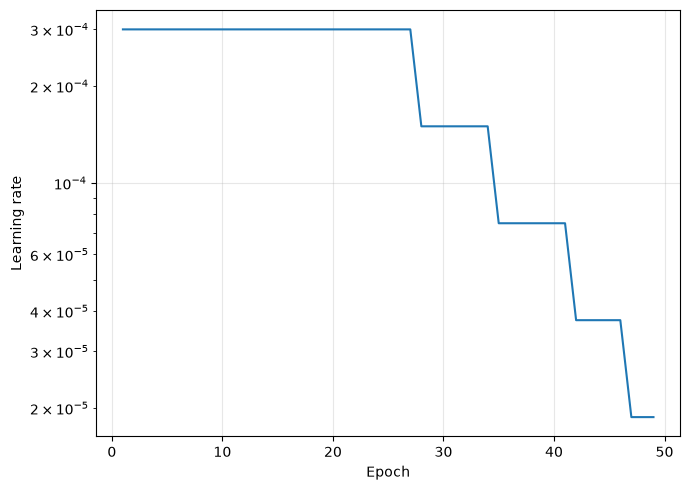

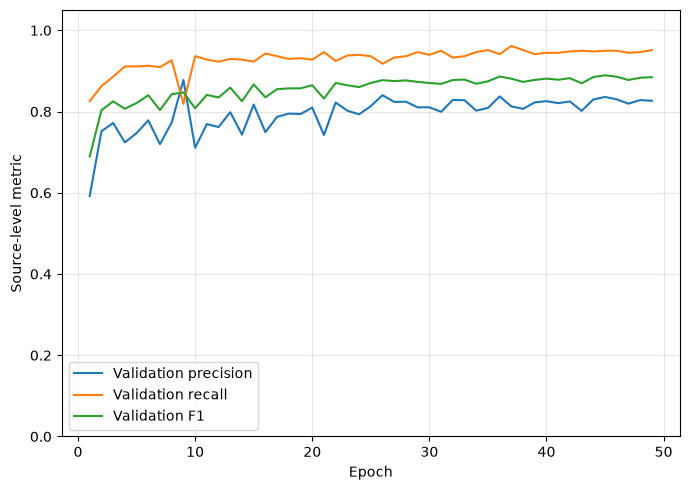

In [17]:
epochs=np.arange(1,len(history.history["loss"])+1)

plt.figure(figsize=(7,5))
plt.plot(epochs,history.history["loss"],label="Train loss")
plt.plot(epochs,history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(np.arange(1,len(lr_logger.values)+1),lr_logger.values)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

metric_epochs=np.arange(1,len(detection_logger.f1)+1)

plt.figure(figsize=(7,5))
plt.plot(metric_epochs,detection_logger.precision,label="Validation precision")
plt.plot(metric_epochs,detection_logger.recall,label="Validation recall")
plt.plot(metric_epochs,detection_logger.f1,label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Source-level metric")
plt.ylim(0,1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Reload best model and inspect prediction

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2360
Best-model test loss: 0.23595856130123138


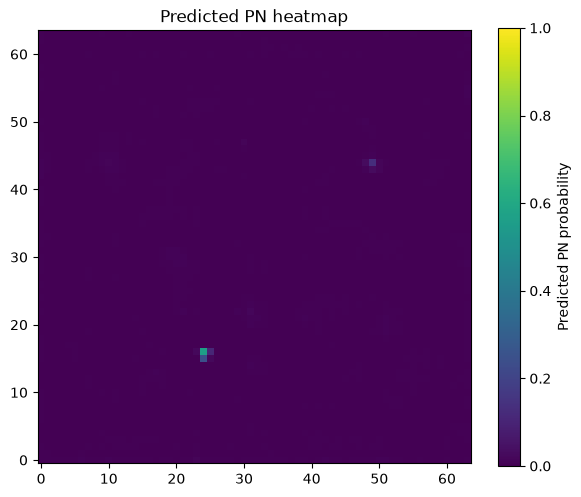

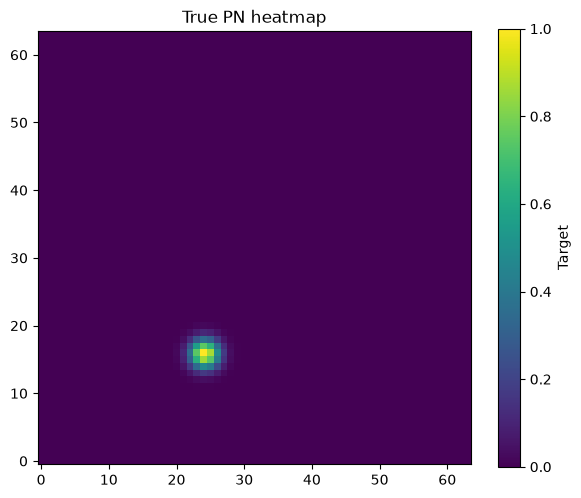

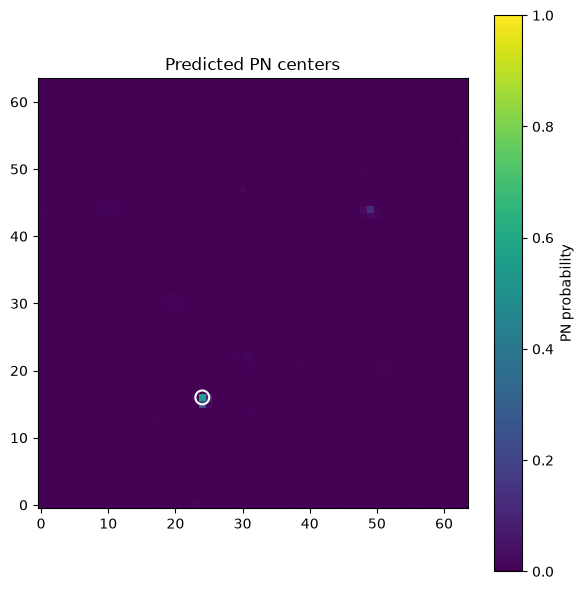

In [18]:
model=keras.models.load_model(
    MODEL_PATH,
    custom_objects={"center_focal_loss":center_focal_loss}
)

test_loss=model.evaluate(test_ds,verbose=1)
print("Best-model test loss:",test_loss)

i=min(50,len(X_test)-1)
pred=model.predict(X_test[i:i+1],verbose=0)[0,:,:,0]
truth=Y_test[i,:,:,0]

plt.figure(figsize=(6,5))
plt.imshow(pred,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="Predicted PN probability")
plt.title("Predicted PN heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
plt.imshow(truth,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="Target")
plt.title("True PN heatmap")
plt.tight_layout()
plt.show()

detections=find_pn_centers(pred,PEAK_THRESHOLD,MIN_DISTANCE)

plt.figure(figsize=(6,6))
plt.imshow(pred,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="PN probability")
if len(detections):
    plt.scatter(detections[:,0],detections[:,1],facecolors="none",edgecolors="white",s=100,linewidths=1.5)
plt.title("Predicted PN centers")
plt.tight_layout()
plt.show()

## Select detection threshold on validation set only

E0000 00:00:1789413842.218857 3223179 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1789413847.252446 3223179 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

threshold  precision  recall  F1
0.10       0.585      0.975   0.731
0.15       0.691      0.973   0.808
0.20       0.737      0.970   0.838
0.25       0.777      0.965   0.861
0.30       0.813      0.961   0.881
0.35       0.827      0.945   0.882
0.40       0.846      0.921   0.882
0.45       0.871      0.904   0.887
0.50       0.889      0.878   0.883
0.55       0.915      0.854   0.884
0.60       0.923      0.809   0.862
0.65       0.939      0.748   0.833
0.70       0.952      0.706   0.811
0.75       0.967      0.631   0.763
0.80       0.991      0.542   0.701
0.85       0.992      0.435   0.604
0.90       0.995      0.326   0.491
Best validation threshold: 0.45000000000000007


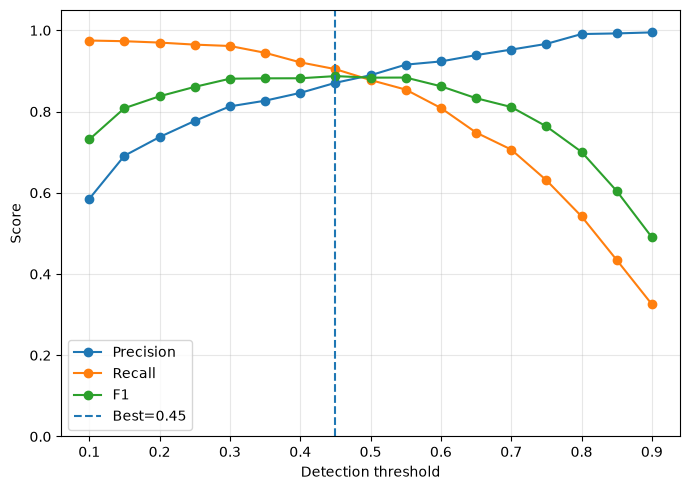

In [19]:
thresholds=np.arange(0.10,0.91,0.05)
results=[]

for threshold in thresholds:
    m=evaluate_detector(
        model,X_val,Y_val,
        threshold=float(threshold),
        min_distance=MIN_DISTANCE,
        match_tolerance=MATCH_TOLERANCE,
        verbose=0
    )
    results.append([threshold,m["precision"],m["recall"],m["f1"]])

results=np.asarray(results,dtype=np.float64)

print("threshold  precision  recall  F1")
for row in results:
    print(f"{row[0]:.2f}       {row[1]:.3f}      {row[2]:.3f}   {row[3]:.3f}")

best_index=np.argmax(results[:,3])
best_threshold=float(results[best_index,0])
print("Best validation threshold:",best_threshold)

plt.figure(figsize=(7,5))
plt.plot(results[:,0],results[:,1],marker="o",label="Precision")
plt.plot(results[:,0],results[:,2],marker="o",label="Recall")
plt.plot(results[:,0],results[:,3],marker="o",label="F1")
plt.axvline(best_threshold,linestyle="--",label=f"Best={best_threshold:.2f}")
plt.xlabel("Detection threshold")
plt.ylabel("Score")
plt.ylim(0,1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final held-out test evaluation

In [20]:
final_metrics=evaluate_detector(
    model,X_test,Y_test,
    threshold=best_threshold,
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE,
    verbose=1
)

print("Final test metrics:")
for key,value in final_metrics.items():
    if key!="localization_errors":
        print(f"{key}: {value}")

print("\nFalse positives by negative type:")
negative_subset_fp_rate(model,X_test,Y_test,types_test,best_threshold)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Final test metrics:
TP: 542
FP: 85
FN: 57
TN: 452
negative_images: 496
negative_images_with_FP: 44
specificity: 0.9112903225806451
false_positive_image_rate: 0.08870967741935484
precision: 0.8644338118022329
recall: 0.9048414023372288
f1: 0.8841761827079935
mean_localization_error: 0.14760147035121918
median_localization_error: 0.0
rmse_localization_error: 0.3841893672943115
std_localization_error: 0.35470449924468994

False positives by negative type:
negative_type     N     image_FP_rate
compact_nonpn     473   0.093
background         23   0.000


## Save normalization and experiment configuration

In [21]:
np.savez(
    NORM_PATH,
    transform=np.asarray("asinh_zscore"),
    line_names=np.asarray(line_names),
    flux_scale=np.float64(FLUX_SCALE),
    asinh_percentile=np.float64(ASINH_PERCENTILE),
    asinh_scale=np.asarray(asinh_scale,dtype=np.float64),
    channel_means=np.asarray(channel_means,dtype=np.float64),
    channel_stds=np.asarray(channel_stds,dtype=np.float64),
    detection_threshold=np.float64(best_threshold)
)

config={
    "architecture":"Residual U-Net",
    "residual_block":"2x Conv3x3-BN with identity/projection shortcut",
    "feature_widths":[32,64,128,256],
    "seed":SEED,
    "data_path":str(DATA_PATH),
    "model_path":str(MODEL_PATH),
    "batch_size":BATCH_SIZE,
    "initial_learning_rate":LEARNING_RATE,
    "weight_decay":WEIGHT_DECAY,
    "clipnorm":CLIPNORM,
    "max_epochs":MAX_EPOCHS,
    "checkpoint_monitor":"val_loss",
    "flux_scale":FLUX_SCALE,
    "asinh_percentile":ASINH_PERCENTILE,
    "dropout":0.20,
    "peak_threshold_initial":PEAK_THRESHOLD,
    "best_validation_threshold":best_threshold,
    "min_distance":MIN_DISTANCE,
    "match_tolerance":MATCH_TOLERANCE,
    "line_names":[str(x) for x in line_names],
    "train_size":int(len(train_idx)),
    "val_size":int(len(val_idx)),
    "test_size":int(len(test_idx))
}

with open(CONFIG_PATH,"w") as f:
    json.dump(config,f,indent=2)

print("Saved normalization:",NORM_PATH)
print("Saved config:",CONFIG_PATH)

Saved normalization: PN_ResUNet_normalization_v4.3.npz
Saved config: PN_ResUNet_training_config_v4.3.json


## Reproducibility checksums

In [22]:
def sha256_file(path,chunk_size=1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            chunk=f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

print("Dataset SHA256:",sha256_file(DATA_PATH))
print("Model SHA256:",sha256_file(MODEL_PATH))
print("Training complete.")

Dataset SHA256: 9f33f4f44ef4131ab7ff771c40ac0fe3dcf1d39fd8292a08e4908e0180fff5ae
Model SHA256: 4139be7d4c31432897f501a00cf2d5060e3a71b4fb6644b48f31685d1b3b38da
Training complete.
